# Exploratory Data Analysis

This notebook describes observed patterns in the validated UCI Appliances Energy Prediction dataset. The raw CSV is read only. Datetimes and temporary time labels are created in memory; no rows or columns are removed, and no cleaned data is saved. These summaries are exploratory, not finalized model features. Correlation describes association and does not establish causation.

The `rv1` and `rv2` columns are retained but treated as random/questionable variables, not physical drivers. No occupancy is supplied or inferred.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

candidate_roots = [Path.cwd(), *Path.cwd().parents]
PROJECT_ROOT = next(
    (root for root in candidate_roots if (root / 'data/raw/energydata_complete.csv').is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Could not locate data/raw/energydata_complete.csv from the current directory or its parents')

DATASET_PATH = PROJECT_ROOT / 'data' / 'raw' / 'energydata_complete.csv'
raw = pd.read_csv(DATASET_PATH)
if 'date' not in raw.columns or 'Appliances' not in raw.columns:
    raise KeyError('Expected date and Appliances columns')
eda = raw.copy()
eda['date'] = pd.to_datetime(eda['date'], errors='raise')
chronological_in_file = bool(eda['date'].is_monotonic_increasing)
eda = eda.sort_values('date', kind='stable').reset_index(drop=True)
eda['hour'] = eda['date'].dt.hour
eda['day_of_week'] = eda['date'].dt.dayofweek
eda['day_name'] = eda['date'].dt.day_name()
eda['month_period'] = eda['date'].dt.to_period('M')
eda['date_only'] = eda['date'].dt.date
eda['is_weekend'] = eda['date'].dt.dayofweek >= 5
print(f'Dataset: {DATASET_PATH.relative_to(PROJECT_ROOT)}')
print(f'Shape: {raw.shape}; chronological in original file: {chronological_in_file}')
print(f'Observed date range: {eda["date"].min()} to {eda["date"].max()}')
print(f'Rows retained for analysis: {len(eda)}')

Dataset: data\raw\energydata_complete.csv
Shape: (19735, 29); chronological in original file: True
Observed date range: 2016-01-11 17:00:00 to 2016-05-27 18:00:00
Rows retained for analysis: 19735


## Target Distribution

Summaries and plots describe `Appliances` as recorded. The boxplot is descriptive: no observations are removed or relabeled as errors.

In [2]:
target = eda['Appliances']
target_summary = target.describe()
target_percentiles = target.quantile([0.50, 0.75, 0.90, 0.95, 0.99])
target_skewness = float(target.skew())
print('Appliances descriptive statistics:')
display(target_summary)
print('Requested percentiles:')
display(target_percentiles.rename(index={0.50: '50th', 0.75: '75th', 0.90: '90th', 0.95: '95th', 0.99: '99th'}))
print(f'Skewness: {target_skewness:.6f}')
if target_skewness > 0:
    distribution_shape = 'positively (right) skewed'
elif target_skewness < 0:
    distribution_shape = 'negatively (left) skewed'
else:
    distribution_shape = 'approximately symmetric by the skewness measure'
print(f'Distribution description from skewness sign: {distribution_shape}')

Appliances descriptive statistics:


count    19735.000000
mean        97.694958
std        102.524891
min         10.000000
25%         50.000000
50%         60.000000
75%        100.000000
max       1080.000000
Name: Appliances, dtype: float64

Requested percentiles:


50th     60.0
75th    100.0
90th    196.0
95th    330.0
99th    576.6
Name: Appliances, dtype: float64

Skewness: 3.386367
Distribution description from skewness sign: positively (right) skewed


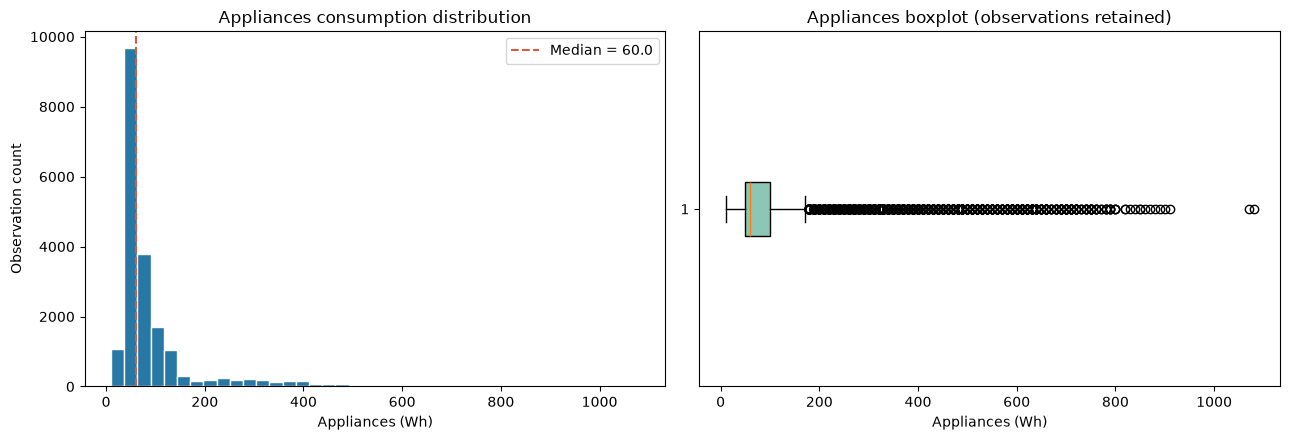

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].hist(target, bins=40, color='#2878A5', edgecolor='white')
axes[0].set(title='Appliances consumption distribution', xlabel='Appliances (Wh)', ylabel='Observation count')
axes[0].axvline(target.median(), color='#D45D3F', linestyle='--', label=f'Median = {target.median():.1f}')
axes[0].legend()
axes[1].boxplot(target, orientation='horizontal', patch_artist=True, boxprops={'facecolor': '#8CC7B5'})
axes[1].set(title='Appliances boxplot (observations retained)', xlabel='Appliances (Wh)')
fig.tight_layout()
plt.show()

## Consumption Over Time

The first panel shows all observed 10-minute target values; daily mean and daily maximum summaries make longer-term variation easier to inspect. Aggregation is only for display and does not replace the underlying observations.

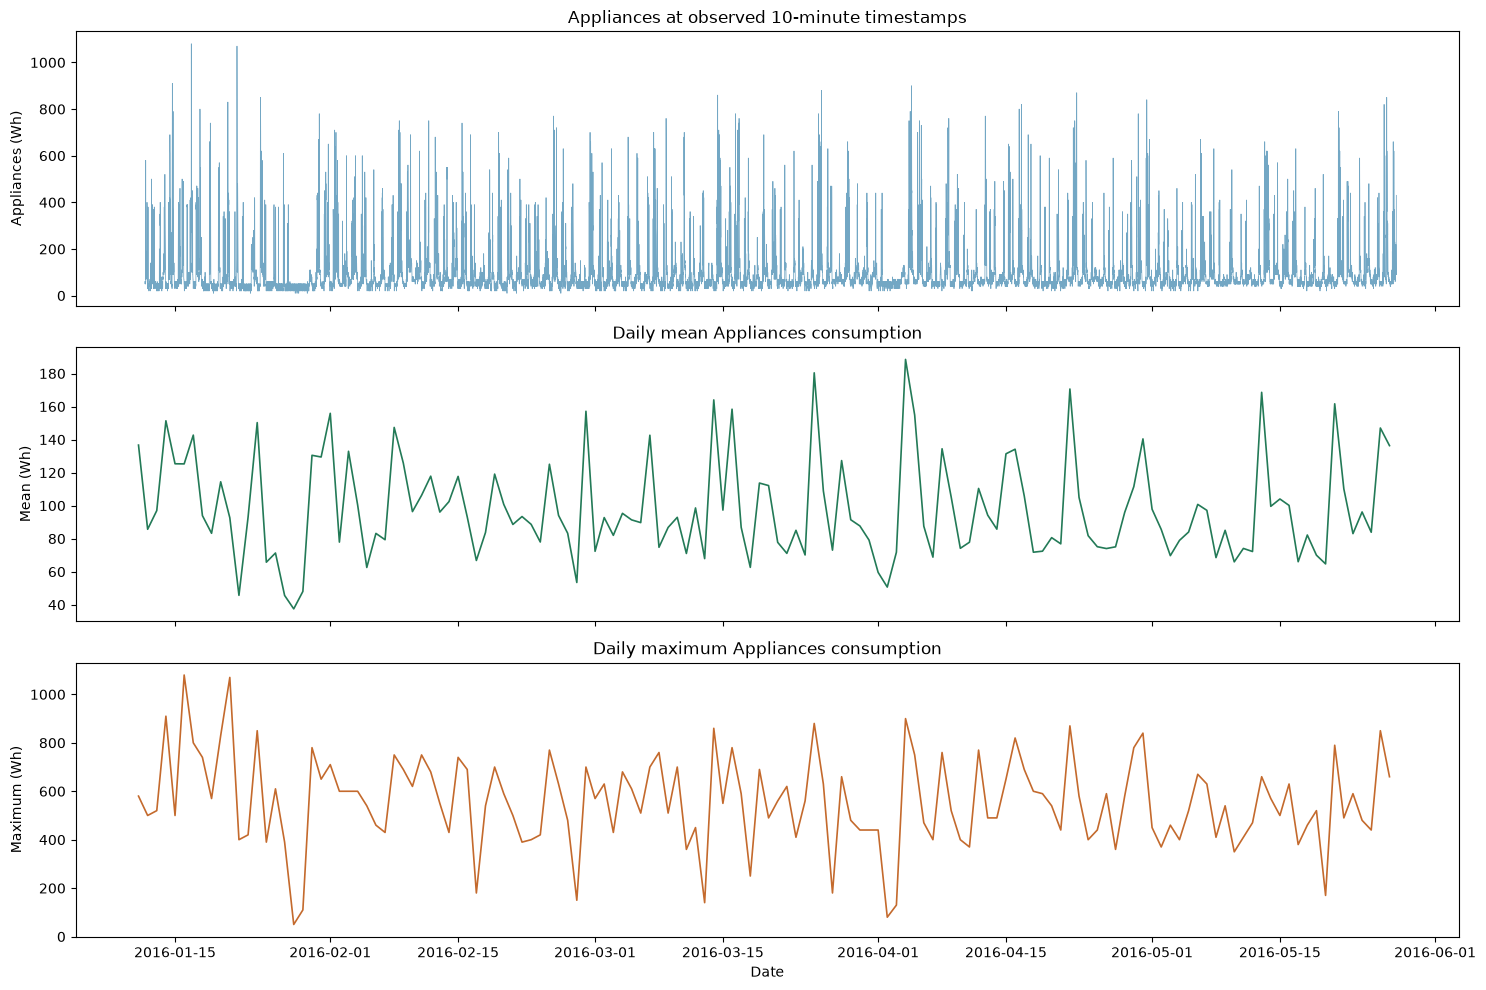

Daily summaries cover 138 observed dates.


In [5]:
daily_consumption = eda.groupby('date_only', sort=True)['Appliances'].agg(['mean', 'max'])
fig, axes = plt.subplots(3, 1, figsize=(15, 10), sharex=True)
axes[0].plot(eda['date'], target, color='#2878A5', linewidth=0.55, alpha=0.65)
axes[0].set(title='Appliances at observed 10-minute timestamps', ylabel='Appliances (Wh)')
axes[1].plot(daily_consumption.index, daily_consumption['mean'], color='#237A57', linewidth=1.2)
axes[1].set(title='Daily mean Appliances consumption', ylabel='Mean (Wh)')
axes[2].plot(daily_consumption.index, daily_consumption['max'], color='#C46A2D', linewidth=1.2)
axes[2].set(title='Daily maximum Appliances consumption', ylabel='Maximum (Wh)', xlabel='Date')
fig.tight_layout()
plt.show()
print(f'Daily summaries cover {len(daily_consumption)} observed dates.')

Visual inspection shows a lower-consumption baseline interrupted by sharp peaks and substantial short-timescale fluctuations. The daily mean and maximum also vary across the observed dates. The hourly summary below shows a recurring within-day pattern in this collection period; these observations do not explain its causes.

## Hourly Consumption Pattern

Hourly groups use the timestamp for descriptive comparison only; they are not proposed as finalized forecasting features.

,mean,median
hour,,
0,52.785888,50.0
1,51.326034,50.0
2,49.075426,50.0
3,48.236010,50.0
4,49.355231,50.0
5,52.737226,50.0
6,57.712895,50.0
7,78.649635,60.0
8,106.143552,60.0


Highest mean: hour 18 (190.365 Wh)
Lowest mean: hour 03 (48.236 Wh)
Highest median: hour 18 (120.000 Wh)


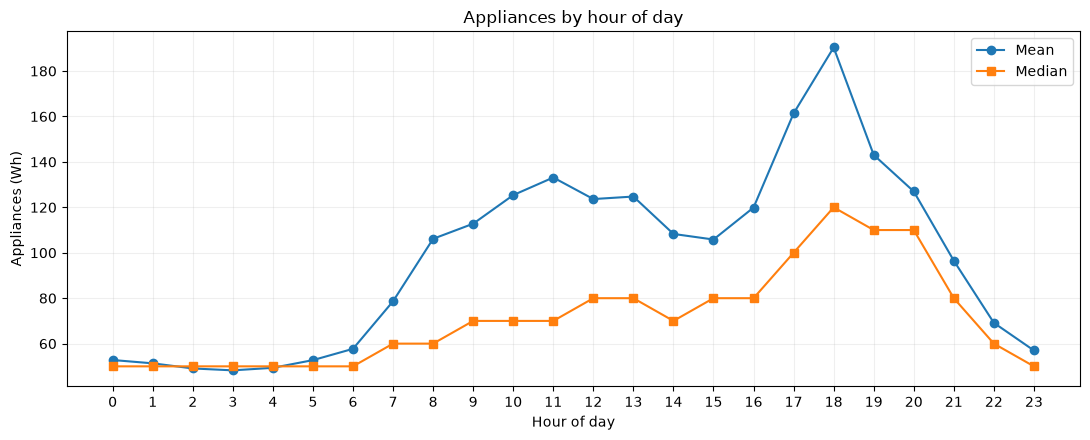

In [6]:
hourly_summary = eda.groupby('hour')['Appliances'].agg(['mean', 'median']).reindex(range(24))
display(hourly_summary)
highest_mean_hour = int(hourly_summary['mean'].idxmax())
lowest_mean_hour = int(hourly_summary['mean'].idxmin())
highest_median_hour = int(hourly_summary['median'].idxmax())
print(f'Highest mean: hour {highest_mean_hour:02d} ({hourly_summary.loc[highest_mean_hour, "mean"]:.3f} Wh)')
print(f'Lowest mean: hour {lowest_mean_hour:02d} ({hourly_summary.loc[lowest_mean_hour, "mean"]:.3f} Wh)')
print(f'Highest median: hour {highest_median_hour:02d} ({hourly_summary.loc[highest_median_hour, "median"]:.3f} Wh)')
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(hourly_summary.index, hourly_summary['mean'], marker='o', label='Mean')
ax.plot(hourly_summary.index, hourly_summary['median'], marker='s', label='Median')
ax.set(xticks=range(24), xlabel='Hour of day', ylabel='Appliances (Wh)', title='Appliances by hour of day')
ax.legend()
ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()

## Day-of-Week Analysis

Days are displayed Monday through Sunday. Weekday/weekend summaries are descriptive comparisons; they do not establish occupancy or explain why consumption differs.

,mean,median
day_name,,
Monday,111.450684,60.0
Tuesday,87.125000,60.0
Wednesday,89.930556,70.0
Thursday,90.434028,60.0
Friday,104.622144,60.0
Saturday,106.246345,70.0
Sunday,94.915936,60.0


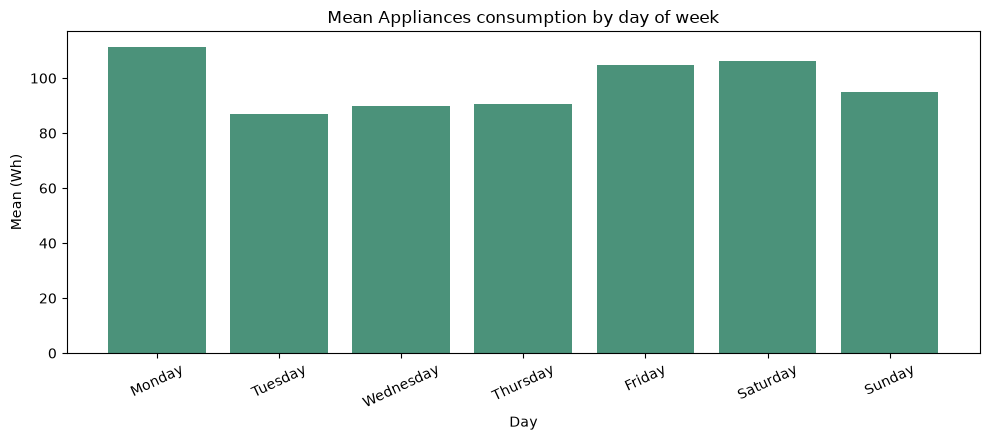

Weekday/weekend descriptive comparison:


,mean,median,count
is_weekend,,,
Weekdays (Mon-Fri),96.587674,60.0,14263
Weekend (Sat-Sun),100.581140,70.0,5472


In [7]:
weekday_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
weekday_type = pd.CategoricalDtype(categories=weekday_order, ordered=True)
eda['day_name'] = eda['day_name'].astype(weekday_type)
weekday_summary = eda.groupby('day_name', observed=False)['Appliances'].agg(['mean', 'median']).reindex(weekday_order)
display(weekday_summary)
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(weekday_summary.index, weekday_summary['mean'], color='#4B927A')
ax.set(title='Mean Appliances consumption by day of week', ylabel='Mean (Wh)', xlabel='Day')
ax.tick_params(axis='x', rotation=25)
fig.tight_layout()
plt.show()
weekday_weekend = eda.groupby('is_weekend', observed=True)['Appliances'].agg(['mean', 'median', 'count'])
weekday_weekend.index = weekday_weekend.index.map({False: 'Weekdays (Mon-Fri)', True: 'Weekend (Sat-Sun)'})
print('Weekday/weekend descriptive comparison:')
display(weekday_weekend)

## Month and Observed Period

Monthly values are shown only for year-month periods present in the data. The collection window is limited, so these results cannot support general seasonal conclusions beyond the observed period.

,mean,median
month_period,,
2016-01,97.026010,50.0
2016-02,100.945881,60.0
2016-03,96.953405,60.0
2016-04,98.888889,60.0
2016-05,94.199325,60.0


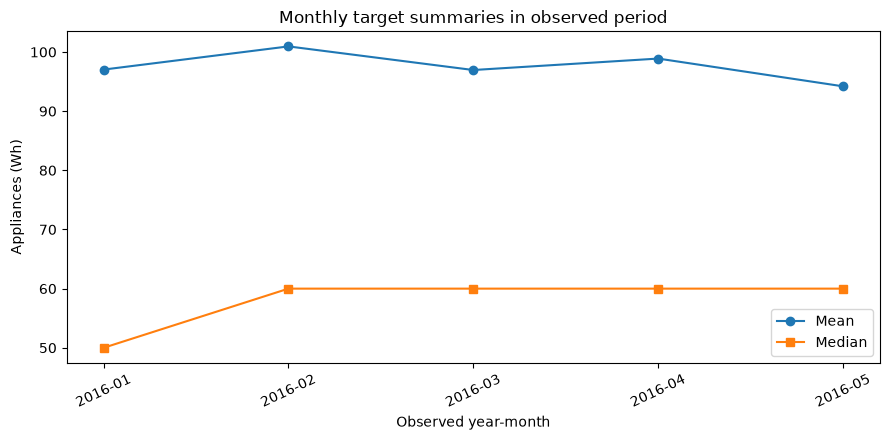

Months observed: 2016-01, 2016-02, 2016-03, 2016-04, 2016-05
Seasonal interpretation is limited to these observed months.


In [8]:
monthly_summary = eda.groupby('month_period', sort=True)['Appliances'].agg(['mean', 'median'])
display(monthly_summary)
fig, ax = plt.subplots(figsize=(9, 4.5))
monthly_labels = monthly_summary.index.astype(str)
x_positions = np.arange(len(monthly_summary))
ax.plot(x_positions, monthly_summary['mean'], marker='o', label='Mean')
ax.plot(x_positions, monthly_summary['median'], marker='s', label='Median')
ax.set(xticks=x_positions, xticklabels=monthly_labels, xlabel='Observed year-month', ylabel='Appliances (Wh)', title='Monthly target summaries in observed period')
ax.tick_params(axis='x', rotation=25)
ax.legend()
fig.tight_layout()
plt.show()
print(f'Months observed: {", ".join(monthly_labels)}')
print('Seasonal interpretation is limited to these observed months.')

## Temperature Relationships

These plots and Pearson coefficients describe pairwise associations for outdoor temperature (`T_out`) and representative indoor sensor `T1`. Correlation does not demonstrate causation.

Pearson correlation with Appliances:


T_out    0.099155
T1       0.055447
Name: Pearson r, dtype: float64

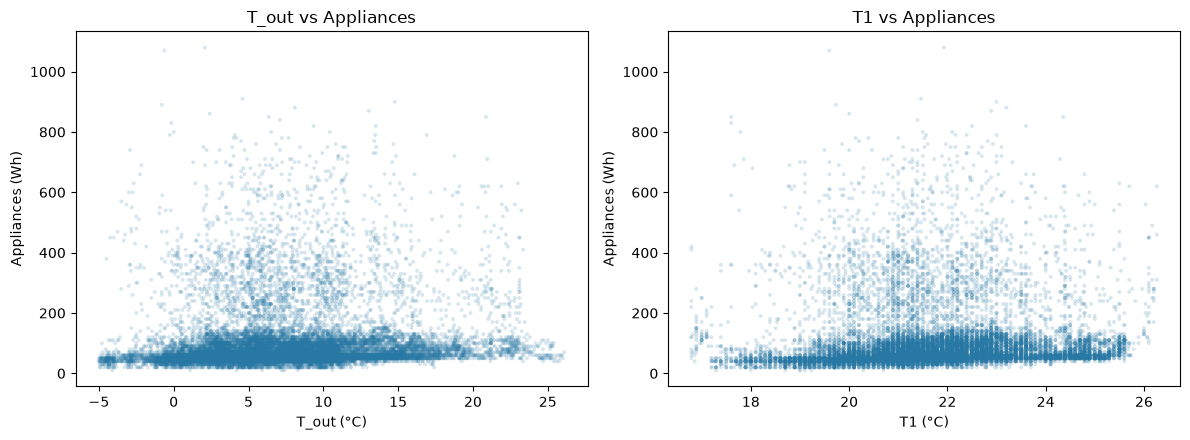

In [9]:
temperature_variables = ['T_out', 'T1']
temperature_correlations = {
    column: float(eda[column].corr(eda['Appliances'], method='pearson'))
    for column in temperature_variables
}
print('Pearson correlation with Appliances:')
display(pd.Series(temperature_correlations, name='Pearson r'))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, column in zip(axes, temperature_variables):
    ax.scatter(eda[column], eda['Appliances'], s=8, alpha=0.18, color='#2878A5', edgecolors='none')
    ax.set(xlabel=f'{column} (°C)', ylabel='Appliances (Wh)', title=f'{column} vs Appliances')
fig.tight_layout()
plt.show()

## Humidity Relationships

`RH_out` and representative indoor humidity sensor `RH_1` are compared with the target. These descriptive correlations do not imply that humidity causes consumption changes.

Pearson correlation with Appliances:


RH_out   -0.152282
RH_1      0.086031
Name: Pearson r, dtype: float64

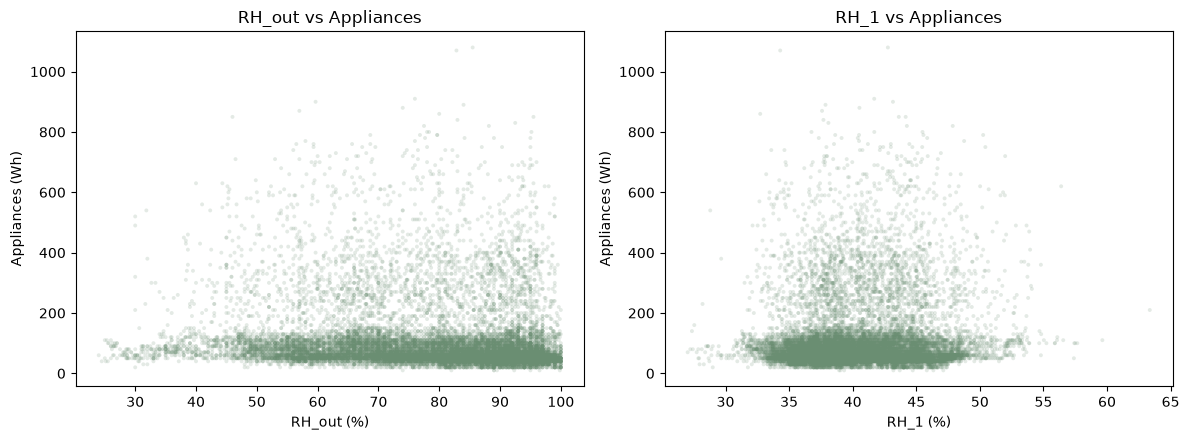

In [10]:
humidity_variables = ['RH_out', 'RH_1']
humidity_correlations = {
    column: float(eda[column].corr(eda['Appliances'], method='pearson'))
    for column in humidity_variables
}
print('Pearson correlation with Appliances:')
display(pd.Series(humidity_correlations, name='Pearson r'))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, column in zip(axes, humidity_variables):
    ax.scatter(eda[column], eda['Appliances'], s=8, alpha=0.18, color='#6A8E72', edgecolors='none')
    ax.set(xlabel=f'{column} (%)', ylabel='Appliances (Wh)', title=f'{column} vs Appliances')
fig.tight_layout()
plt.show()

## Lighting Analysis

`lights` is analyzed as a separate energy-use measurement and compared with `Appliances`, the target. It is not an occupancy measure.

Pearson correlation between lights and Appliances: 0.197278
Observed lights-value distribution:


lights
0     15252
10     2212
20     1624
30      559
40       77
50        9
60        1
70        1
Name: observation_count, dtype: int64

,mean,median,count
lights,,,
0,86.584710,60.0,15252
10,129.037071,80.0,2212
20,136.428571,90.0,1624
30,150.214669,100.0,559
40,182.337662,130.0,77
50,178.888889,90.0,9
60,580.000000,580.0,1
70,230.000000,230.0,1


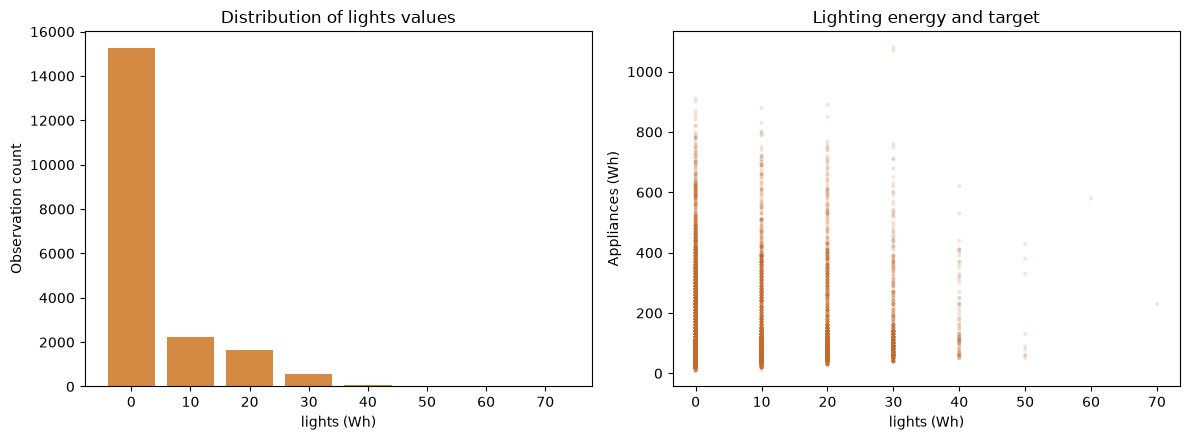

In [11]:
lighting_correlation = float(eda['lights'].corr(eda['Appliances'], method='pearson'))
lighting_distribution = eda['lights'].value_counts().sort_index()
lighting_by_level = eda.groupby('lights', sort=True)['Appliances'].agg(['mean', 'median', 'count'])
print(f'Pearson correlation between lights and Appliances: {lighting_correlation:.6f}')
print('Observed lights-value distribution:')
display(lighting_distribution.rename('observation_count'))
display(lighting_by_level)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].bar(lighting_distribution.index.astype(str), lighting_distribution.values, color='#D48A42')
axes[0].set(title='Distribution of lights values', xlabel='lights (Wh)', ylabel='Observation count')
axes[1].scatter(eda['lights'], eda['Appliances'], s=8, alpha=0.18, color='#C46A2D', edgecolors='none')
axes[1].set(title='Lighting energy and target', xlabel='lights (Wh)', ylabel='Appliances (Wh)')
fig.tight_layout()
plt.show()

## Numeric Correlation Analysis

The numeric matrix excludes `date` and temporary time labels. `Appliances` is the target. `rv1` and `rv2` are excluded from the main matrix because they are identical and random/questionable; their correlations are reported separately. Correlations describe association, not causation.

Main matrix: 26 numeric columns; date and rv1/rv2 excluded.
Appliances correlations, strongest positive to strongest negative:


,Pearson r
lights,0.197278
T2,0.120073
T6,0.117638
T_out,0.099155
Windspeed,0.087122
RH_1,0.086031
T3,0.085060
T1,0.055447
T4,0.040281
T8,0.039572


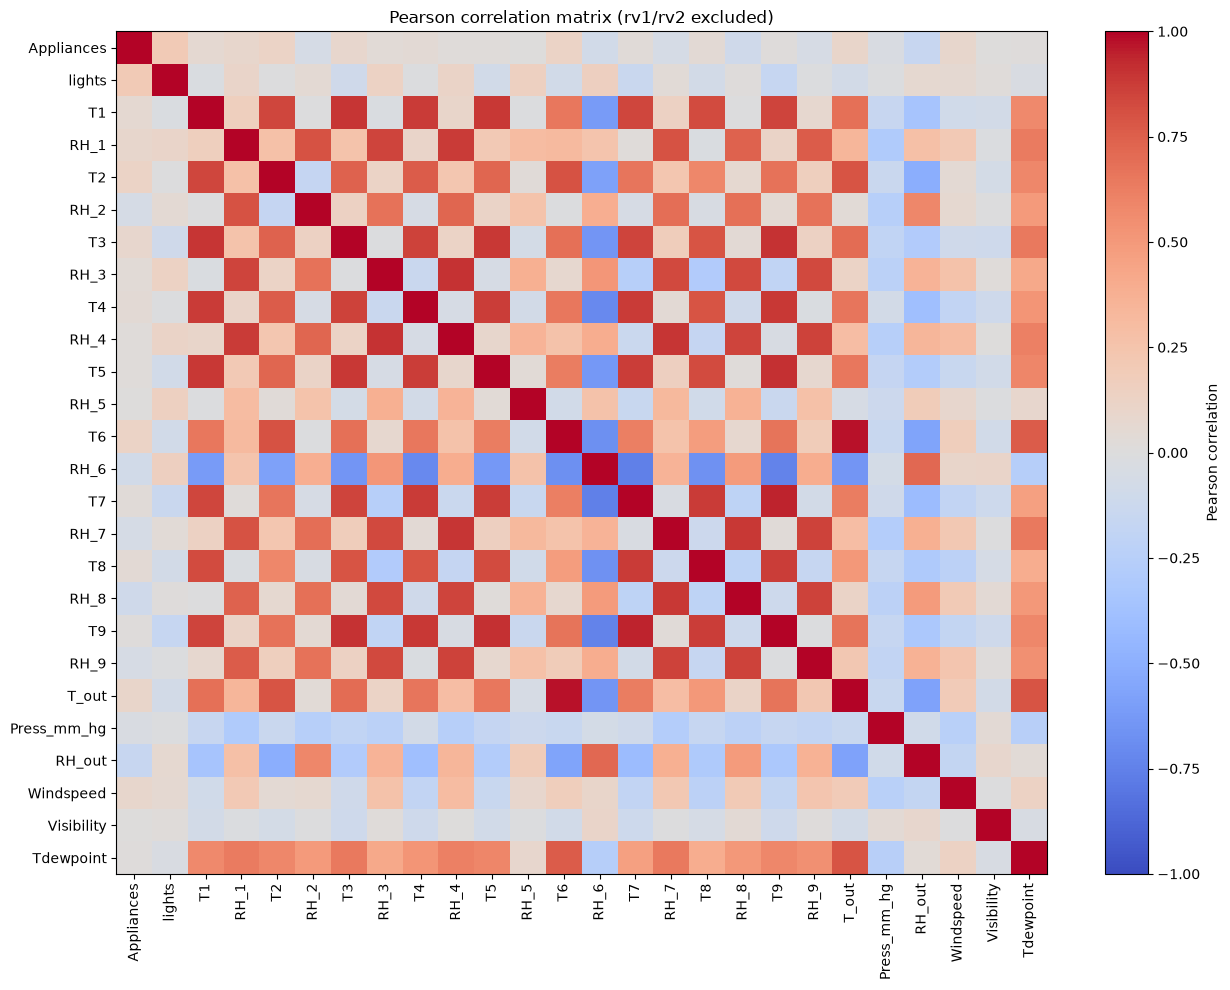

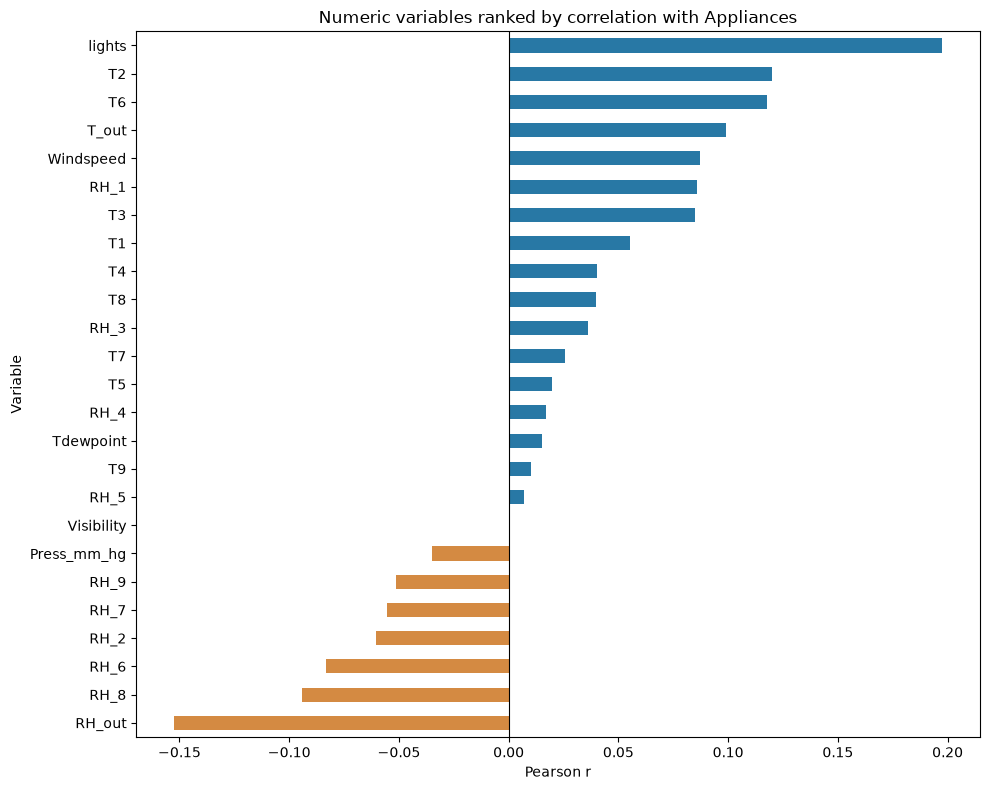

Five strongest absolute correlations (descriptive only):


,Pearson r
lights,0.197278
RH_out,-0.152282
T2,0.120073
T6,0.117638
T_out,0.099155


In [12]:
RANDOM_QUESTIONABLE = ['rv1', 'rv2']
numeric_columns = [column for column in raw.select_dtypes(include='number').columns if column not in RANDOM_QUESTIONABLE]
if 'Appliances' not in numeric_columns:
    raise TypeError('Appliances must be numeric for correlation analysis')
correlation_matrix = raw[numeric_columns].corr(method='pearson')
target_correlations = correlation_matrix['Appliances'].drop('Appliances').sort_values(ascending=False)
print(f'Main matrix: {len(numeric_columns)} numeric columns; date and rv1/rv2 excluded.')
print('Appliances correlations, strongest positive to strongest negative:')
display(target_correlations.to_frame('Pearson r'))
fig, ax = plt.subplots(figsize=(13, 10))
image = ax.imshow(correlation_matrix, cmap='coolwarm', vmin=-1, vmax=1, aspect='auto')
ax.set_xticks(np.arange(len(numeric_columns)), labels=numeric_columns, rotation=90)
ax.set_yticks(np.arange(len(numeric_columns)), labels=numeric_columns)
ax.set_title('Pearson correlation matrix (rv1/rv2 excluded)')
fig.colorbar(image, ax=ax, label='Pearson correlation')
fig.tight_layout()
plt.show()
ordered_correlations = target_correlations.sort_values()
bar_colors = np.where(ordered_correlations >= 0, '#2878A5', '#D48A42')
fig, ax = plt.subplots(figsize=(10, 8))
ordered_correlations.plot(kind='barh', ax=ax, color=bar_colors)
ax.set(title='Numeric variables ranked by correlation with Appliances', xlabel='Pearson r', ylabel='Variable')
ax.axvline(0, color='black', linewidth=0.8)
fig.tight_layout()
plt.show()
strongest_by_absolute = target_correlations.reindex(target_correlations.abs().sort_values(ascending=False).index).head(5)
print('Five strongest absolute correlations (descriptive only):')
display(strongest_by_absolute.to_frame('Pearson r'))

## Peak-Consumption Analysis

The 95th percentile is an exploratory threshold only. Observations at or above it are counted by hour and weekday; it is not a recommendation or operational threshold.

95th-percentile threshold: 330.000 Wh
Observations >= threshold: 1001 (5.072%) of 19735
High-consumption observations by hour (top five):


hour
18    140
17    115
11     84
10     75
19     70
Name: count, dtype: int64

High-consumption observations by weekday:


day_name
Monday       201
Tuesday      116
Wednesday    101
Thursday     117
Friday       190
Saturday     161
Sunday       115
Name: count, dtype: int64

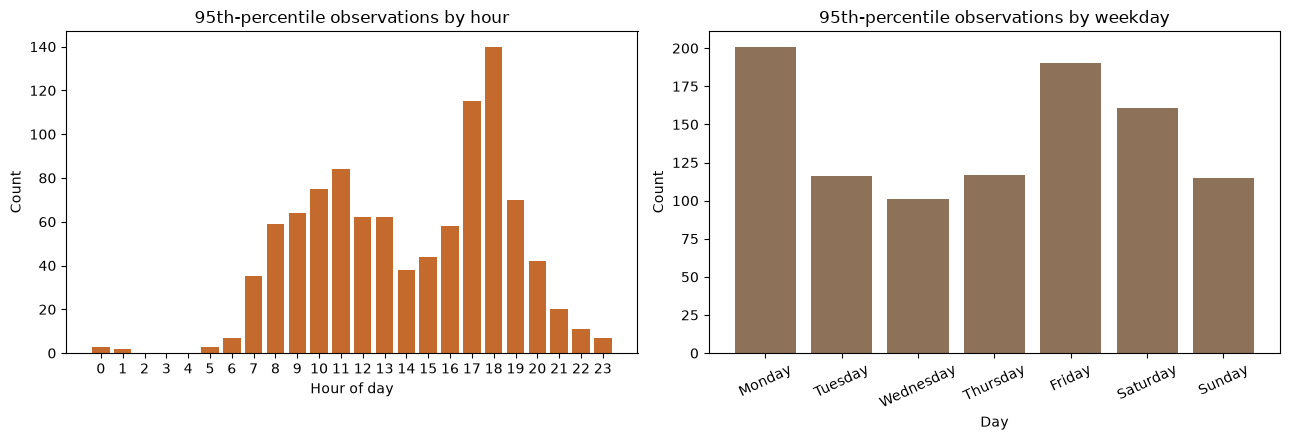

In [13]:
peak_threshold_95 = float(eda['Appliances'].quantile(0.95))
high_consumption_mask = eda['Appliances'] >= peak_threshold_95
high_consumption_count = int(high_consumption_mask.sum())
high_consumption_percentage = float(high_consumption_mask.mean() * 100)
peak_by_hour = eda.loc[high_consumption_mask].groupby('hour').size().reindex(range(24), fill_value=0)
peak_by_weekday = eda.loc[high_consumption_mask].groupby('day_name', observed=False).size().reindex(weekday_order, fill_value=0)
print(f'95th-percentile threshold: {peak_threshold_95:.3f} Wh')
print(f'Observations >= threshold: {high_consumption_count} ({high_consumption_percentage:.3f}%) of {len(eda)}')
print('High-consumption observations by hour (top five):')
display(peak_by_hour.sort_values(ascending=False, kind='stable').head(5).rename('count'))
print('High-consumption observations by weekday:')
display(peak_by_weekday.rename('count'))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].bar(peak_by_hour.index, peak_by_hour.values, color='#C46A2D')
axes[0].set(title='95th-percentile observations by hour', xlabel='Hour of day', ylabel='Count', xticks=range(24))
axes[1].bar(peak_by_weekday.index, peak_by_weekday.values, color='#8D7158')
axes[1].set(title='95th-percentile observations by weekday', xlabel='Day', ylabel='Count')
axes[1].tick_params(axis='x', rotation=25)
fig.tight_layout()
plt.show()

## Outlier Analysis

The IQR rule flags values outside the conventional 1.5 × IQR bounds. Observations are retained: high consumption may be a legitimate operational peak, not an error.

In [14]:
q1 = float(eda['Appliances'].quantile(0.25))
q3 = float(eda['Appliances'].quantile(0.75))
target_iqr = q3 - q1
lower_iqr_bound = q1 - 1.5 * target_iqr
upper_iqr_bound = q3 + 1.5 * target_iqr
outside_iqr_mask = (eda['Appliances'] < lower_iqr_bound) | (eda['Appliances'] > upper_iqr_bound)
iqr_outlier_count = int(outside_iqr_mask.sum())
iqr_outlier_percentage = float(outside_iqr_mask.mean() * 100)
print(f'Q1: {q1:.3f}; Q3: {q3:.3f}; IQR: {target_iqr:.3f}')
print(f'Lower bound: {lower_iqr_bound:.3f}; upper bound: {upper_iqr_bound:.3f}')
print(f'Observations outside bounds: {iqr_outlier_count} ({iqr_outlier_percentage:.3f}%)')
print('No observations were removed; high values may be legitimate consumption events.')

Q1: 50.000; Q3: 100.000; IQR: 50.000
Lower bound: -25.000; upper bound: 175.000
Observations outside bounds: 2138 (10.834%)
No observations were removed; high values may be legitimate consumption events.


## `rv1` / `rv2` Diagnostic

These columns were identical row by row in Phase 2. Correlations are included only as a diagnostic; they are random/questionable variables, not physical energy drivers, and neither column is removed.

In [15]:
RANDOM_QUESTIONABLE = ['rv1', 'rv2']
rv1_rv2_identical = bool(np.array_equal(eda['rv1'].to_numpy(), eda['rv2'].to_numpy(), equal_nan=True))
rv1_rv2_correlation = float(eda['rv1'].corr(eda['rv2'], method='pearson'))
rv_target_correlations = eda[RANDOM_QUESTIONABLE + ['Appliances']].corr(method='pearson')['Appliances'].drop('Appliances')
print(f'rv1 and rv2 identical row by row: {rv1_rv2_identical}')
print(f'Pearson correlation rv1 vs rv2: {rv1_rv2_correlation:.6f}')
print('Pearson correlations with Appliances (random/questionable; not physical drivers):')
display(rv_target_correlations.rename('Pearson r'))

rv1 and rv2 identical row by row: True
Pearson correlation rv1 vs rv2: 1.000000
Pearson correlations with Appliances (random/questionable; not physical drivers):


rv1   -0.011145
rv2   -0.011145
Name: Pearson r, dtype: float64

## Key EDA Findings

The following summary is generated from the calculations above. It separates observed facts from possible interpretations and limitations; it makes no causal claims or recommendations.

In [16]:
top_correlation_text = '; '.join(f'{name}: {value:.3f}' for name, value in strongest_by_absolute.items())
peak_hour_text = ', '.join(
    f'{int(hour):02d}:00 ({int(count)})'
    for hour, count in peak_by_hour.sort_values(ascending=False, kind='stable').head(3).items()
)
peak_day_text = ', '.join(
    f'{day} ({int(count)})'
    for day, count in peak_by_weekday.sort_values(ascending=False, kind='stable').head(3).items()
)
weekday_mean = float(weekday_weekend.loc['Weekdays (Mon-Fri)', 'mean'])
weekend_mean = float(weekday_weekend.loc['Weekend (Sat-Sun)', 'mean'])
weekday_median = float(weekday_weekend.loc['Weekdays (Mon-Fri)', 'median'])
weekend_median = float(weekday_weekend.loc['Weekend (Sat-Sun)', 'median'])
observed_findings = [
    f'- **Target distribution:** mean {eda["Appliances"].mean():.3f} Wh, median {eda["Appliances"].median():.3f} Wh, sample standard deviation {eda["Appliances"].std():.3f} Wh, skewness {target_skewness:.3f} ({distribution_shape}).',
    f'- **Temporal pattern:** mean is highest at {highest_mean_hour:02d}:00 and lowest at {lowest_mean_hour:02d}:00; highest hourly median is at {highest_median_hour:02d}:00. The observed date range is {eda["date"].min().date()} to {eda["date"].max().date()}.',
    f'- **Weekday/weekend:** weekday mean/median are {weekday_mean:.3f}/{weekday_median:.3f} Wh; weekend mean/median are {weekend_mean:.3f}/{weekend_median:.3f} Wh.',
    f'- **Strongest absolute main-matrix correlations with Appliances:** {top_correlation_text}. These are descriptive associations.',
    f'- **Temperature:** Pearson r is {temperature_correlations["T_out"]:.3f} for T_out and {temperature_correlations["T1"]:.3f} for T1.',
    f'- **Humidity:** Pearson r is {humidity_correlations["RH_out"]:.3f} for RH_out and {humidity_correlations["RH_1"]:.3f} for RH_1.',
    f'- **Lighting:** Pearson r between lights and Appliances is {lighting_correlation:.3f}; lights is separate energy use, not occupancy.',
    f'- **Exploratory peaks:** 95th-percentile threshold {peak_threshold_95:.3f} Wh; {high_consumption_count} observations ({high_consumption_percentage:.3f}%) are at or above it. Most frequent hours: {peak_hour_text}; weekdays: {peak_day_text}.',
    f'- **IQR rule:** {iqr_outlier_count} observations ({iqr_outlier_percentage:.3f}%) fall outside [{lower_iqr_bound:.3f}, {upper_iqr_bound:.3f}] Wh; none were removed.',
    f'- **Questionable variables:** rv1 and rv2 identical row by row; mutual Pearson r is {rv1_rv2_correlation:.3f}. They are not interpreted as physical drivers.',
]
limitations = [
    'Possible interpretation: observed patterns and associations can motivate later research questions but do not identify causes or justify control actions.',
    f'The dataset covers {len(monthly_summary)} observed month(s), from {eda["date"].min().date()} to {eda["date"].max().date()}; seasonal conclusions cannot be generalized beyond this collection period.',
    'No occupancy observations are used or inferred. No preprocessing, feature selection, forecasting, or model evaluation was performed.',
]
summary_markdown = '### Observed facts\n\n' + '\n'.join(observed_findings) + '\n\n### Possible interpretation and limitations\n\n' + '\n'.join(f'- {item}' for item in limitations)
display(Markdown(summary_markdown))

### Observed facts

- **Target distribution:** mean 97.695 Wh, median 60.000 Wh, sample standard deviation 102.525 Wh, skewness 3.386 (positively (right) skewed).
- **Temporal pattern:** mean is highest at 18:00 and lowest at 03:00; highest hourly median is at 18:00. The observed date range is 2016-01-11 to 2016-05-27.
- **Weekday/weekend:** weekday mean/median are 96.588/60.000 Wh; weekend mean/median are 100.581/70.000 Wh.
- **Strongest absolute main-matrix correlations with Appliances:** lights: 0.197; RH_out: -0.152; T2: 0.120; T6: 0.118; T_out: 0.099. These are descriptive associations.
- **Temperature:** Pearson r is 0.099 for T_out and 0.055 for T1.
- **Humidity:** Pearson r is -0.152 for RH_out and 0.086 for RH_1.
- **Lighting:** Pearson r between lights and Appliances is 0.197; lights is separate energy use, not occupancy.
- **Exploratory peaks:** 95th-percentile threshold 330.000 Wh; 1001 observations (5.072%) are at or above it. Most frequent hours: 18:00 (140), 17:00 (115), 11:00 (84); weekdays: Monday (201), Friday (190), Saturday (161).
- **IQR rule:** 2138 observations (10.834%) fall outside [-25.000, 175.000] Wh; none were removed.
- **Questionable variables:** rv1 and rv2 identical row by row; mutual Pearson r is 1.000. They are not interpreted as physical drivers.

### Possible interpretation and limitations

- Possible interpretation: observed patterns and associations can motivate later research questions but do not identify causes or justify control actions.
- The dataset covers 5 observed month(s), from 2016-01-11 to 2016-05-27; seasonal conclusions cannot be generalized beyond this collection period.
- No occupancy observations are used or inferred. No preprocessing, feature selection, forecasting, or model evaluation was performed.